# 04 — Regularised linear models: ridge, lasso, elastic net

Phase 4 showed that plain OLS works well (grouped-CV R² 0.845), but some coefficients are unstable. RAM vs storage and screen vs weight swap importance depending on what else is in the model. **Regularisation** adds a penalty on the size of the coefficients to the least-squares objective, trading a little bias for a lot less variance:

- **Ridge:** minimise ‖y − Xw‖² + α‖w‖² (sum of *squared* coefficients). It shrinks all coefficients smoothly towards 0.
- **Lasso:** minimise (1/2n)‖y − Xw‖² + α‖w‖₁ (sum of *absolute* coefficients). It can set coefficients **exactly** to 0, so it also selects features.
- **Elastic net:** a mix of the two penalties.

α (written λ in lectures) controls the penalty strength: α → 0 gives OLS, and a very large α shrinks everything to 0. We choose α by **grouped 5-fold cross-validation on the training set**, as in Phase 4.

**Pipeline.** All preprocessing sits inside a scikit-learn **Pipeline**, so in every CV fold it is fitted on that fold's training part only:
- `StandardScaler` on the numeric features, so that the penalty treats all features fairly. Otherwise a feature measured in mAh (thousands) would get a tiny coefficient, and hence a tiny penalty, just because of its units.
- `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` on brand and chip group. Here we keep **all** dummies (no reference category). With OLS that would make XᵀX singular, but the penalty makes the solution unique, as section 1 shows.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.exceptions import ConvergenceWarning

from features import NUMERIC_FEATURES, CATEGORICAL_FEATURES
from split import load_train_test, cv_folds

pd.set_option("display.width", 200)
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
train, _ = load_train_test(include_web_lookup=True)
train_name, _ = load_train_test(include_web_lookup=False)
print("training phones:", len(train), "| name-only:", len(train_name))

training phones: 558 | name-only: 555


In [2]:
def make_pipeline(model):
    # Scaling and one-hot encoding live INSIDE the pipeline, so in every CV fold they are
    # fitted on that fold's training part only (no information leaks from the validation part).
    pre = ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ])
    return Pipeline([("pre", pre), ("model", model)])

def coef_series(pipe):
    # Fitted coefficients with readable names, e.g. "log2_ram", "brand_Apple"
    names = pipe.named_steps["pre"].get_feature_names_out()
    names = [n.replace("num__", "").replace("cat__", "") for n in names]
    return pd.Series(pipe.named_steps["model"].coef_, index=names)

def score(y_true_log, y_pred_log):
    y_true_log, y_pred_log = np.asarray(y_true_log), np.asarray(y_pred_log)
    # R² = 1 − RSS / TSS, on the log scale
    r2 = 1 - np.sum((y_true_log - y_pred_log) ** 2) / np.sum((y_true_log - y_true_log.mean()) ** 2)
    price_true, price_pred = np.exp(y_true_log), np.exp(y_pred_log)   # back to rupees
    return {"R²": r2,
            "median % error": 100 * np.median(np.abs(price_pred / price_true - 1)),
            "MAE (₹)": np.mean(np.abs(price_pred - price_true))}

## 1. Ridge regression
### 1a. Choosing α by grouped cross-validation
We try 50 values of α spaced evenly on a log scale from 0.001 to 1000 (`np.logspace(-3, 3, 50)`) and pick the one with the lowest mean validation error. The error is the **mean squared error (MSE)** on log price.

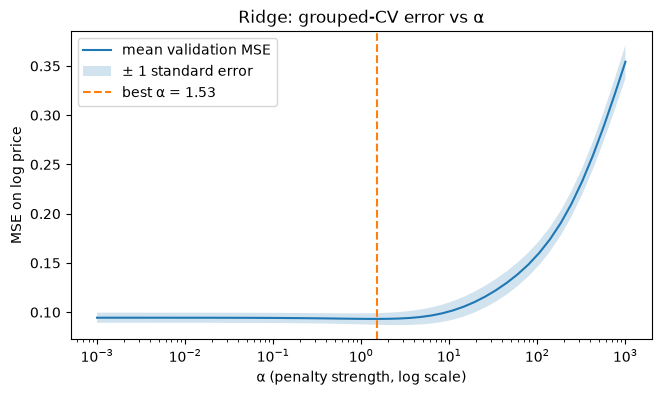

best α = 1.526, CV MSE = 0.0932; MSE at smallest α (≈ OLS) = 0.0944; at largest α = 0.3543


In [3]:
ridge_alphas = np.logspace(-3, 3, 50)
# Grid search over α with the saved grouped folds; score = −MSE on log price (higher is better)
ridge_search = GridSearchCV(make_pipeline(Ridge()), {"model__alpha": ridge_alphas},
                            cv=cv_folds(train), scoring="neg_mean_squared_error")
ridge_search.fit(train[FEATURES], train["log_price"])
mse_mean = -ridge_search.cv_results_["mean_test_score"]
mse_std = ridge_search.cv_results_["std_test_score"]
best_ridge_alpha = ridge_search.best_params_["model__alpha"]

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(ridge_alphas, mse_mean, label="mean validation MSE")
ax.fill_between(ridge_alphas, mse_mean - mse_std / np.sqrt(5), mse_mean + mse_std / np.sqrt(5),
                alpha=0.2, label="± 1 standard error")
ax.axvline(best_ridge_alpha, color="tab:orange", linestyle="--", label=f"best α = {best_ridge_alpha:.3g}")
ax.set_xscale("log")
ax.set(title="Ridge: grouped-CV error vs α", xlabel="α (penalty strength, log scale)", ylabel="MSE on log price")
ax.legend()
plt.show()
print(f"best α = {best_ridge_alpha:.4g}, CV MSE = {mse_mean.min():.4f}; "
      f"MSE at smallest α (≈ OLS) = {mse_mean[0]:.4f}; at largest α = {mse_mean[-1]:.4f}")

**Takeaway:** the error curve is flat from α = 0.001 up to about α = 3, then rises steeply as heavy shrinkage starts to remove real signal. The best α is **1.53**, with CV MSE 0.0932 against 0.0944 at α ≈ 0 (i.e. OLS), about a **1 % improvement**. This fits Phase 4: collinearity among our features is only moderate (condition number 17 for the numeric features), so OLS was not badly overfitting, and ridge has little variance to remove.

### 1b. Coefficient paths
A **coefficient path** shows how each coefficient changes as α grows. Numeric coefficients are in standardised units: the change in log price for a one-standard-deviation increase in the feature.

In [4]:
# Refit ridge on the whole training set for every α and keep all coefficients
path = {}
for a in ridge_alphas:
    path[a] = coef_series(make_pipeline(Ridge(alpha=a)).fit(train[FEATURES], train["log_price"]))
path = pd.DataFrame(path).T   # one row per α, one column per coefficient

PATH_SPECS = ["log2_ram", "log2_storage", "weight_g", "screen_in", "battery_mah", "year", "front_mp", "main_back_mp"]
HIGHLIGHT = ["brand_Apple", "brand_Infinix", "brand_Google", "brand_Samsung"]

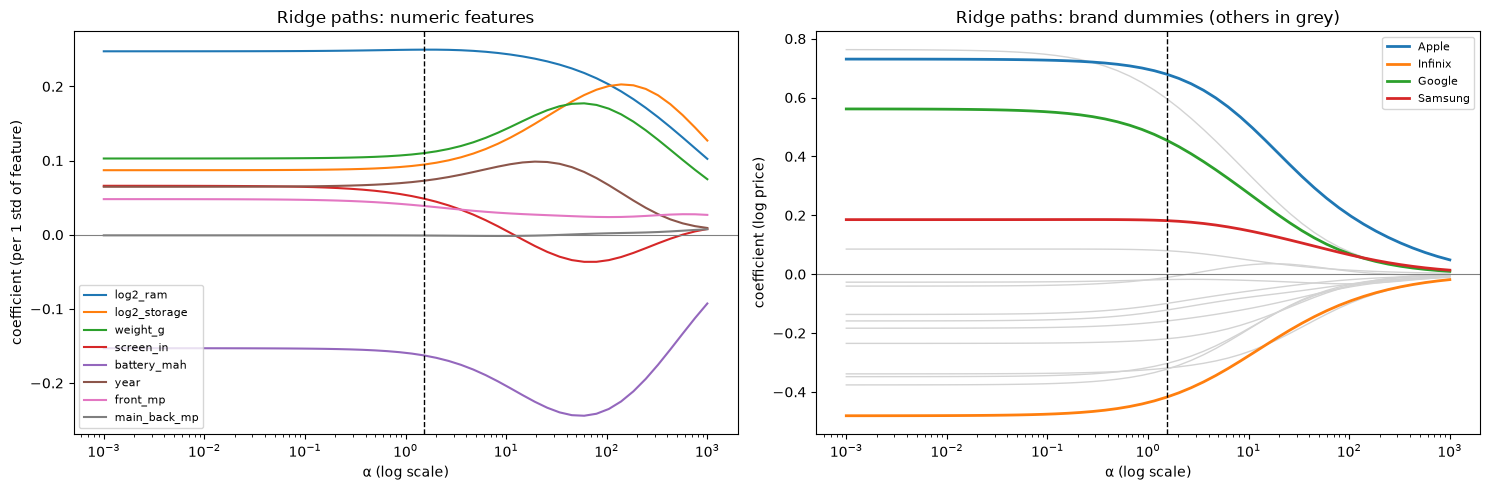

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for col in PATH_SPECS:
    axes[0].plot(ridge_alphas, path[col], label=col)
axes[0].set(title="Ridge paths: numeric features", xlabel="α (log scale)", ylabel="coefficient (per 1 std of feature)")

for col in path.columns:
    if col.startswith("brand_") and col not in HIGHLIGHT:
        axes[1].plot(ridge_alphas, path[col], color="lightgray", linewidth=1)
for col in HIGHLIGHT:
    axes[1].plot(ridge_alphas, path[col], linewidth=2, label=col.replace("brand_", ""))
axes[1].set(title="Ridge paths: brand dummies (others in grey)", xlabel="α (log scale)", ylabel="coefficient (log price)")

for ax in axes:
    ax.set_xscale("log")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(best_ridge_alpha, color="black", linestyle="--", linewidth=1)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Takeaway:** at the chosen α (dashed line) every coefficient is still almost at its OLS value; the visible shrinkage only begins around α ≈ 3–10. Two patterns are worth noting as α grows:
- **RAM and storage converge.** The RAM coefficient falls while storage *rises*, until near α ≈ 100 they are about equal. This is ridge's typical behaviour with correlated features: when the data cannot tell them apart, the penalty prefers to **share** the effect between them (two medium coefficients have a smaller sum of squares than one big and one small). Weight and year rise for a while for the same reason.
- **Brand coefficients shrink towards each other.** Apple and Google (high premiums) and Infinix (low) all move towards 0, i.e. towards "brand does not matter", only at very large α.

### 1c. Why ridge stabilises: the eigenvalue view
Write the (centred) design matrix as X and let XᵀX have eigenvalues λ₁ ≥ … ≥ λ_p with eigenvectors v₁ … v_p (the "directions" in feature space). In that basis the ridge solution is the OLS solution with the component along each direction vᵢ multiplied by

**shrink factor = λᵢ / (λᵢ + α)**.

- A direction with a **large** λᵢ is well supported by the data (features vary a lot along it). Its factor is close to 1, so it is hardly shrunk.
- A direction with a **small** λᵢ is poorly supported. OLS estimates it with huge variance (∝ 1/λᵢ), and ridge shrinks it strongly.
- A direction with λᵢ = 0 (an exact redundancy) gets factor 0, so ridge simply ignores it. That is why keeping **all** brand and chip dummies is fine: the dummies of one category always sum to 1, which after centring is an exact zero-eigenvalue direction.

We compute the eigenvalues of the centred, preprocessed training matrix (sklearn's `Ridge` centres X internally to fit the intercept) and the shrink factor at the chosen α.

In [6]:
pre = make_pipeline(Ridge()).named_steps["pre"].fit(train[FEATURES])
Xp = pre.transform(train[FEATURES])
names = [n.replace("num__", "").replace("cat__", "") for n in pre.get_feature_names_out()]
Xc = Xp - Xp.mean(axis=0)                       # centre each column, as Ridge does internally
eigvals, eigvecs = np.linalg.eigh(Xc.T @ Xc)    # eigenvalues come out smallest first
shrink = eigvals / (eigvals + best_ridge_alpha)  # fraction of each direction ridge keeps
print(f"{len(eigvals)} directions; {np.sum(eigvals < 1e-8)} have eigenvalue ~0 (one per one-hot category set)\n")

nonzero = np.where(eigvals > 1e-8)[0]
show = list(nonzero[:4]) + [len(eigvals) - 3, len(eigvals) - 2, len(eigvals) - 1]   # 4 smallest non-zero, 3 largest
print(f"{'eigenvalue λ':>12}  {'kept at α=' + format(best_ridge_alpha, '.3g'):>12}   top 3 features in this direction")
for i in show:
    top3 = np.argsort(-np.abs(eigvecs[:, i]))[:3]       # the 3 largest loadings of eigenvector i
    loadings = ", ".join(f"{names[j]} ({eigvecs[j, i]:+.2f})" for j in top3)
    print(f"{eigvals[i]:12.3f}  {shrink[i]:12.3f}   {loadings}")

33 directions; 2 have eigenvalue ~0 (one per one-hot category set)

eigenvalue λ  kept at α=1.53   top 3 features in this direction
       1.952         0.561   chip_group_kirin (+0.80), brand_Other (-0.49), chip_group_tensor (-0.17)
       2.591         0.629   chip_group_tensor (+0.71), brand_Google (-0.61), chip_group_unisoc (-0.15)
       5.170         0.772   brand_Nokia (-0.74), brand_Xiaomi (+0.33), chip_group_unisoc (+0.28)
       8.075         0.841   brand_Nokia (+0.52), brand_Lenovo (-0.45), brand_Xiaomi (+0.45)
     704.049         0.998   weight_g (-0.53), n_back_cameras (-0.46), front_mp (+0.41)
     873.615         0.998   n_back_cameras (+0.45), battery_mah (-0.43), front_mp (+0.39)
    2098.242         0.999   log2_ram (-0.41), screen_in (-0.41), log2_storage (-0.35)


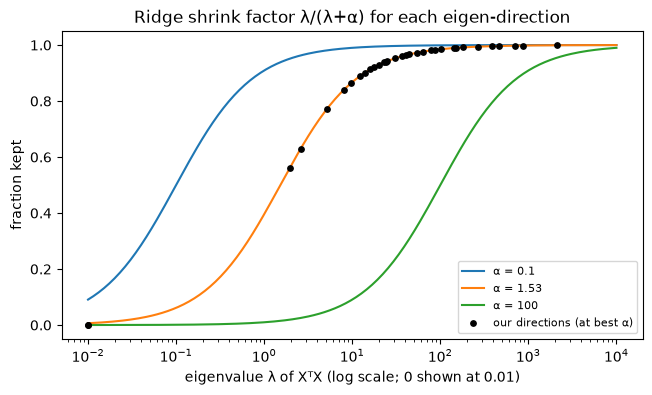

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4))
lam = np.logspace(-2, 4, 200)
for a in [0.1, best_ridge_alpha, 100]:
    ax.plot(lam, lam / (lam + a), label=f"α = {a:.3g}")
ax.scatter(np.clip(eigvals, 1e-2, None), shrink, color="black", s=15, zorder=3, label="our directions (at best α)")
ax.set_xscale("log")
ax.set(title="Ridge shrink factor λ/(λ+α) for each eigen-direction",
       xlabel="eigenvalue λ of XᵀX (log scale; 0 shown at 0.01)", ylabel="fraction kept")
ax.legend(fontsize=8)
plt.show()

**Takeaway:** the 33 preprocessed columns have 33 eigen-directions.
- **Two eigenvalues are exactly 0**, one for the brand dummies and one for the chip dummies (each set sums to 1). OLS has no unique solution along these directions. Ridge's factor 0/(0+α) = 0 simply sets those components to zero, which is why keeping all dummies is harmless here.
- The **smallest non-zero eigenvalues** are 1.95 and 2.59, and their eigenvectors are "Kirin chip vs brand Other" and "Tensor chip vs brand Google". These are the same brand-specific chips that confused Model A: the data barely separates "Huawei's chip" from "Huawei's brand", or "Google's chip" from "Google's brand". At the chosen α ridge keeps only **56 % and 63 %** of these components, so this is where it acts most.
- The largest eigenvalues (700–2100) are broad mixes of the numeric specs (e.g. "more RAM + bigger screen + more storage"). Their factor is 0.998–0.999, i.e. untouched.

So, as in lectures: ridge leaves the well-determined directions alone and shrinks exactly the unstable ones. Here those are the brand-vs-own-chip directions rather than RAM vs storage, whose direction (eigenvalue ≈ 120 in Phase 4's scaling) is still well supported.

## 2. RAM and storage: OLS vs ridge
We now compare the two coefficients that Phase 4 found unstable. To put both models on the same footing we fit them on **exactly the same pipeline** (all dummies, standardised numerics). For OLS that requires a tiny α (1e-6), because the full set of dummies is singular without a penalty. We then convert each coefficient to "% price change for doubling", dividing the standardised coefficient by the standard deviation of log2 RAM / log2 storage.

In [8]:
def doubling_effects(alpha, data):
    pipe = make_pipeline(Ridge(alpha=alpha)).fit(data[FEATURES], data["log_price"])
    coef = coef_series(pipe)
    sd = pd.Series(pipe.named_steps["pre"].named_transformers_["num"].scale_, index=NUMERIC_FEATURES)
    # standardised coefficient / std of the feature = effect of one unit of log2, i.e. one doubling
    b_ram, b_sto = coef["log2_ram"] / sd["log2_ram"], coef["log2_storage"] / sd["log2_storage"]
    return {"RAM ×2 (%)": 100 * (np.exp(b_ram) - 1), "storage ×2 (%)": 100 * (np.exp(b_sto) - 1),
            "both ×2 (%)": 100 * (np.exp(b_ram + b_sto) - 1),
            "RAM coef (std units)": coef["log2_ram"], "storage coef (std units)": coef["log2_storage"]}

ram_sto = pd.DataFrame({"OLS (α≈0)": doubling_effects(1e-6, train),
                        f"Ridge (α={best_ridge_alpha:.3g})": doubling_effects(best_ridge_alpha, train),
                        "Ridge (α=100, heavy)": doubling_effects(100, train)}).T.round(3)
ram_sto

,RAM ×2 (%),storage ×2 (%),both ×2 (%),RAM coef (std units),storage coef (std units)
OLS (α≈0),48.409,10.043,63.315,0.247,0.087
Ridge (α=1.53),48.941,10.967,65.276,0.250,0.095
"Ridge (α=100, heavy)",38.528,24.588,72.589,0.204,0.200


**Takeaway:** at the CV-chosen α, ridge gives practically the **same** answer as OLS: doubling RAM +48.9 % vs +48.4 %, doubling storage +11.0 % vs +10.0 %. The RAM–storage direction is not weak enough for α = 1.53 to move it. Only with heavy shrinkage (α = 100) does ridge pull them together (RAM +38.5 %, storage +24.6 %). The *combined* effect of doubling both stays far more stable (+63 % OLS, +65 % ridge) than either part.

So the honest statement for the report is: *the data clearly says that more memory (RAM and storage together) is worth about +60 % per doubling, but how that splits between RAM and storage is only weakly determined and depends on the model.*

## 3. Lasso
The lasso uses the absolute-value penalty α‖w‖₁. Its corners make it set some coefficients **exactly to zero**, so it performs feature selection. sklearn's lasso divides the squared error by 2n, so its α is on a different scale from ridge's. We search `np.logspace(-4, 0, 50)` instead (0.0001 to 1), which covers the range from "almost OLS" to "everything zero".

In [9]:
lasso_alphas = np.logspace(-4, 0, 50)
with warnings.catch_warnings(record=True) as caught:      # record every warning instead of printing it
    warnings.simplefilter("always", ConvergenceWarning)
    lasso_search = GridSearchCV(make_pipeline(Lasso(max_iter=50000)), {"model__alpha": lasso_alphas},
                                cv=cv_folds(train), scoring="neg_mean_squared_error")
    lasso_search.fit(train[FEATURES], train["log_price"])
    lasso_path = {}
    for a in lasso_alphas:   # refit on the whole training set for every α
        lasso_path[a] = coef_series(make_pipeline(Lasso(alpha=a, max_iter=50000)).fit(train[FEATURES], train["log_price"]))
not_converged = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
print(f"lasso fits that did not converge: {not_converged} (should be 0)")

lasso_path = pd.DataFrame(lasso_path).T
best_lasso_alpha = lasso_search.best_params_["model__alpha"]
n_nonzero = (lasso_path.abs() > 1e-10).sum(axis=1)

lasso fits that did not converge: 0 (should be 0)


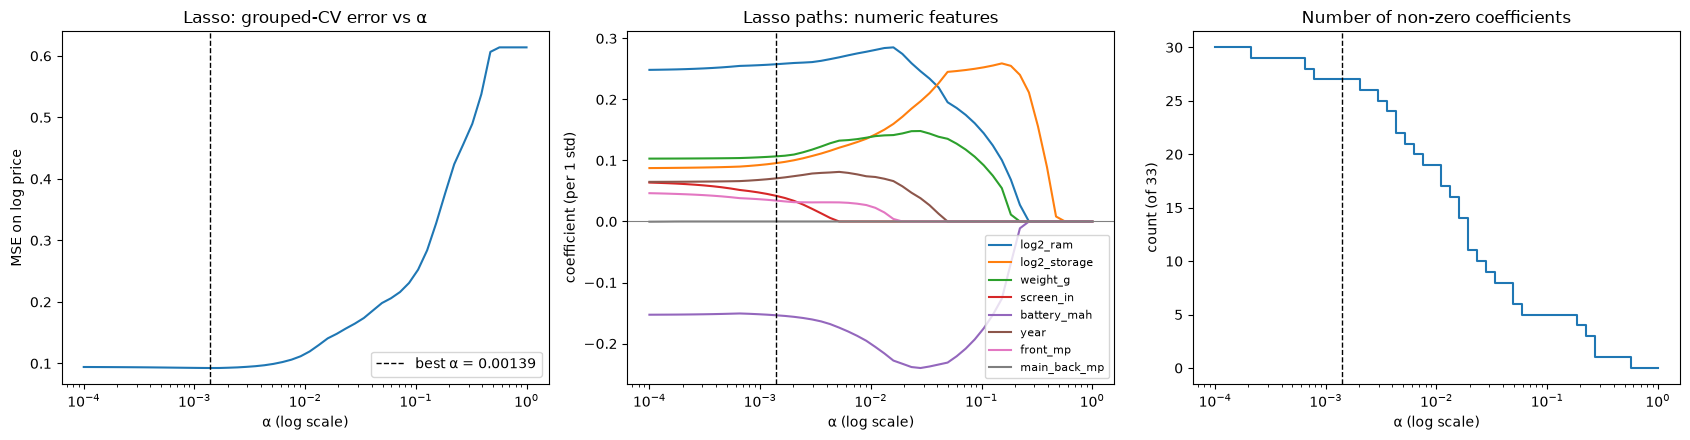

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(lasso_alphas, -lasso_search.cv_results_["mean_test_score"])
axes[0].set(title="Lasso: grouped-CV error vs α", xlabel="α (log scale)", ylabel="MSE on log price")
for col in PATH_SPECS:
    axes[1].plot(lasso_alphas, lasso_path[col], label=col)
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set(title="Lasso paths: numeric features", xlabel="α (log scale)", ylabel="coefficient (per 1 std)")
axes[1].legend(fontsize=8)
axes[2].plot(lasso_alphas, n_nonzero, drawstyle="steps-post")
axes[2].set(title="Number of non-zero coefficients", xlabel="α (log scale)", ylabel=f"count (of {lasso_path.shape[1]})")
for ax in axes:
    ax.set_xscale("log")
    ax.axvline(best_lasso_alpha, color="black", linestyle="--", linewidth=1, label=f"best α = {best_lasso_alpha:.3g}")
axes[0].legend()
fig.tight_layout()
plt.show()

In [11]:
# For each numeric feature: the α at which the lasso sets it to zero for good
drop_alpha = {}
for col in NUMERIC_FEATURES:
    nonzero = (lasso_path[col].abs() > 1e-10).to_numpy()   # one True/False per α, smallest α first
    if not nonzero.any():
        drop_alpha[col] = lasso_alphas[0]          # zero already at the smallest α
    elif nonzero[-1]:
        drop_alpha[col] = np.nan                   # still non-zero at the largest α
    else:
        last = np.where(nonzero)[0].max()          # last α where it is non-zero ...
        drop_alpha[col] = lasso_alphas[last + 1]   # ... so it is dropped at the next α

order = pd.Series(drop_alpha).sort_values()
print("α at which each numeric feature is dropped for good (smaller = dropped earlier = less useful):")
for col, a in order.items():
    print(f"{col:15s} {a:.4f}" if pd.notna(a) else f"{col:15s} never in range")

α at which each numeric feature is dropped for good (smaller = dropped earlier = less useful):
main_back_mp    0.0002
n_back_cameras  0.0036
screen_in       0.0052
front_mp        0.0193
year            0.0494
weight_g        0.2223
battery_mah     0.2683
log2_ram        0.2683
log2_storage    0.5690


In [12]:
lasso_coef = coef_series(lasso_search.best_estimator_)
is_zero = lasso_coef.abs() <= 1e-10
print(f"At the chosen α = {best_lasso_alpha:.4g}: {int((~is_zero).sum())} of {len(lasso_coef)} coefficients are non-zero.\n")
print("Set exactly to ZERO:", ", ".join(lasso_coef[is_zero].index))
print("\nSurviving coefficients (sorted by size):")
print(lasso_coef[~is_zero].sort_values(key=abs, ascending=False).round(4).to_string())

At the chosen α = 0.001389: 27 of 33 coefficients are non-zero.

Set exactly to ZERO: main_back_mp, brand_Nokia, brand_Tecno, chip_group_kirin, chip_group_snapdragon_other, chip_group_tensor

Surviving coefficients (sorted by size):
brand_Apple                         0.7870
brand_Other                         0.6898
brand_Google                        0.6089
chip_group_flagship_sd8_or_apple    0.4559
chip_group_unisoc                  -0.3893
brand_Infinix                      -0.3085
brand_Samsung                       0.2833
chip_group_helio                   -0.2750
log2_ram                            0.2577
brand_Realme                       -0.2465
chip_group_dimensity_high           0.2055
brand_Lenovo                       -0.1916
brand_POCO                         -0.1840
battery_mah                        -0.1537
brand_OnePlus                      -0.1225
chip_group_dimensity_other         -0.1137
weight_g                            0.1067
log2_storage                        

**Takeaway:**
- The CV-best lasso uses a **small** α = 0.0014 and keeps **27 of 33** coefficients. Like ridge, the data prefers little regularisation.
- At that α the lasso sets to exactly zero: **main camera MP** (no information once other specs are known, as in Phase 4), the **Nokia** and **Tecno** brand dummies, and the **Kirin, Tensor and Snapdragon-other** chip dummies. Dropping one dummy per set is just the lasso choosing its own reference categories. Dropping Kirin and Tensor matches the ridge eigen-analysis: those chips are not separable from their brands (Huawei/"Other", Google), so the lasso lets the brand carry the effect.
- **Order in which numeric features drop out** as α grows (earliest = least useful): main camera MP → number of back cameras → screen → front camera → year → weight → RAM and battery → **storage last**. When the penalty forces a choice between the correlated pair RAM/storage, the lasso keeps storage and drops RAM (middle panel). That is the lasso's typical behaviour with correlated features: it keeps one and discards the other, whereas ridge shares the effect between them.

## 4. Elastic net (optional)
The penalty is α · [l1_ratio · ‖w‖₁ + (1 − l1_ratio)/2 · ‖w‖²]: l1_ratio = 1 is the lasso and l1_ratio → 0 approaches ridge. We search l1_ratio ∈ {0.2, 0.5, 0.8} together with α.

In [13]:
enet_grid = {"model__alpha": np.logspace(-4, 0, 30), "model__l1_ratio": [0.2, 0.5, 0.8]}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    enet_search = GridSearchCV(make_pipeline(ElasticNet(max_iter=50000)), enet_grid,
                               cv=cv_folds(train), scoring="neg_mean_squared_error")
    enet_search.fit(train[FEATURES], train["log_price"])
print(f"elastic-net fits that did not converge: {sum(issubclass(w.category, ConvergenceWarning) for w in caught)} (should be 0)")

best_enet = enet_search.best_params_
enet_coef = coef_series(enet_search.best_estimator_)
print(f"best: alpha = {best_enet['model__alpha']:.4g}, l1_ratio = {best_enet['model__l1_ratio']}, "
      f"CV MSE = {-enet_search.best_score_:.4f}; zero coefficients: {int((enet_coef.abs() <= 1e-10).sum())} of {len(enet_coef)}")

elastic-net fits that did not converge: 0 (should be 0)
best: alpha = 0.001743, l1_ratio = 0.8, CV MSE = 0.0925; zero coefficients: 5 of 33


**Takeaway:** the elastic net picks l1_ratio = 0.8 and a small α (0.0017) and zeros 5 coefficients. Its CV error (MSE 0.0925) equals the lasso's and is marginally below ridge's (0.0932), a difference far smaller than the fold-to-fold noise.

## 5. Comparison table (grouped CV on the training set)
The Phase 4 rows are read from `results/cv_phase4.csv`. The new rows use the chosen α refitted inside each fold, with the same folds.

One caution: α was chosen with these same folds, so the regularised models' CV scores are very slightly optimistic. With a single tuning parameter the effect is small, and the untouched test set in Phase 7 gives the unbiased check.

In [14]:
def cross_validate(model, data):
    # Grouped CV with the saved folds: fit the whole pipeline on 4 folds, score on the 5th
    scores = []
    for fit_idx, val_idx in cv_folds(data):
        fit, val = data.iloc[fit_idx], data.iloc[val_idx]
        pipe = make_pipeline(model).fit(fit[FEATURES], fit["log_price"])
        scores.append(score(val["log_price"], pipe.predict(val[FEATURES])))
    return pd.DataFrame(scores)

def summary_row(name, folds):
    # Mean and std of each metric over the 5 folds, in the same columns as results/cv_phase4.csv
    row = {"model": name}
    for metric, col in [("R²", "R2_log"), ("median % error", "median_pct_error"), ("MAE (₹)", "MAE_rupees")]:
        row[col + "_mean"] = folds[metric].mean()
        row[col + "_std"] = folds[metric].std()
    return row

In [15]:
best_models = {
    "Ridge": Ridge(alpha=best_ridge_alpha),
    "Lasso": Lasso(alpha=best_lasso_alpha, max_iter=50000),
    "Elastic net": ElasticNet(alpha=best_enet["model__alpha"], l1_ratio=best_enet["model__l1_ratio"], max_iter=50000),
}
phase4 = pd.read_csv("../results/cv_phase4.csv")   # written by notebook 03
rows = phase4.to_dict("records")
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    for name, model in best_models.items():
        rows.append(summary_row(name, cross_validate(model, train)))
print(f"fits that did not converge: {sum(issubclass(w.category, ConvergenceWarning) for w in caught)} (should be 0)")
comparison = pd.DataFrame(rows)
comparison.to_csv("../results/cv_phase5.csv", index=False)

# Show it as "mean ± std"
pd.DataFrame({"R² (log price)": [f"{r['R2_log_mean']:.3f} ± {r['R2_log_std']:.3f}" for r in rows],
              "median % error": [f"{r['median_pct_error_mean']:.1f} ± {r['median_pct_error_std']:.1f}" for r in rows],
              "MAE (₹)": [f"{r['MAE_rupees_mean']:,.0f} ± {r['MAE_rupees_std']:,.0f}" for r in rows]},
             index=comparison["model"])

fits that did not converge: 0 (should be 0)


,R² (log price),median % error,MAE (₹)
model,,,
Baseline 1: overall mean,-0.006 ± 0.005,59.1 ± 2.4,"29,797 ± 2,812"
Baseline 2: brand mean,0.366 ± 0.056,40.3 ± 3.1,"22,181 ± 2,706"
Model A: specs + chip,0.773 ± 0.039,23.3 ± 1.7,"14,273 ± 2,048"
Model B: specs + chip + brand,0.845 ± 0.018,18.2 ± 2.2,"11,757 ± 1,658"
Ridge,0.847 ± 0.019,18.3 ± 2.4,"11,588 ± 1,767"
Lasso,0.848 ± 0.019,18.0 ± 2.1,"11,633 ± 1,807"
Elastic net,0.848 ± 0.019,18.1 ± 2.0,"11,617 ± 1,813"


**Takeaway:** ridge, lasso and elastic net all reach **R² ≈ 0.848** (0.847–0.848) and a median error of **18.0–18.3 %**, practically the same as OLS Model B (0.845, 18.2 %) and well inside the fold-to-fold standard deviation (± 0.02). **Regularisation does not improve accuracy here** — with 558 phones and 33 columns, and only moderate collinearity, OLS was not overfitting much. Its value in this project is **stability and interpretability**: unique coefficients with all brands kept (needed for the brand-premium analysis in Phase 8) and a principled answer to the redundant-dummy problem. We carry **ridge** forward as the main linear model.

## 6. Robustness: name-only training data
We repeat the α search and the CV scores without the 3 web-lookup phones in the training set.

In [16]:
rob = []
for label, data in [("with web lookup", train), ("name-only", train_name)]:
    search = GridSearchCV(make_pipeline(Ridge()), {"model__alpha": ridge_alphas},
                          cv=cv_folds(data), scoring="neg_mean_squared_error")
    search.fit(data[FEATURES], data["log_price"])
    a = search.best_params_["model__alpha"]
    folds = cross_validate(Ridge(alpha=a), data)
    eff = doubling_effects(a, data)
    rob.append({"model": "Ridge", "data": label, "best α": round(a, 4), "CV R²": round(folds["R²"].mean(), 3),
                "median % error": round(folds["median % error"].mean(), 1),
                "RAM ×2 %": round(eff["RAM ×2 (%)"], 1), "storage ×2 %": round(eff["storage ×2 (%)"], 1)})

In [17]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    for label, data in [("with web lookup", train), ("name-only", train_name)]:
        search = GridSearchCV(make_pipeline(Lasso(max_iter=50000)), {"model__alpha": lasso_alphas},
                              cv=cv_folds(data), scoring="neg_mean_squared_error")
        search.fit(data[FEATURES], data["log_price"])
        a = search.best_params_["model__alpha"]
        folds = cross_validate(Lasso(alpha=a, max_iter=50000), data)
        rob.append({"model": "Lasso", "data": label, "best α": round(a, 4), "CV R²": round(folds["R²"].mean(), 3),
                    "median % error": round(folds["median % error"].mean(), 1),
                    "RAM ×2 %": np.nan, "storage ×2 %": np.nan})
print(f"lasso fits that did not converge: {sum(issubclass(w.category, ConvergenceWarning) for w in caught)} (should be 0)")
rob = pd.DataFrame(rob)
rob

lasso fits that did not converge: 0 (should be 0)


,model,data,best α,CV R²,median % error,RAM ×2 %,storage ×2 %
0,Ridge,with web lookup,1.5264,0.847,18.3,48.9,11.0
1,Ridge,name-only,1.5264,0.848,18.0,49.9,10.3
2,Lasso,with web lookup,0.0014,0.848,18.0,NaN,NaN
3,Lasso,name-only,0.0014,0.849,18.0,NaN,NaN


**Takeaway:** without the web-lookup phones, ridge picks the same α (1.53) and nearly the same CV R² (0.848 vs 0.847). The lasso picks the same α (0.0014) with R² 0.849 vs 0.848. The RAM and storage effects move by about 1 percentage point. The conclusions do not depend on the 7 phones.

## 7. Principal component analysis (PCA) of the specs
The 9 numeric specs overlap: RAM, storage, weight and launch year tend to rise together. **Principal component analysis (PCA)** describes that overlap. It finds new axes, called **principal components (PCs)**, that are combinations of the standardised specs:
- **PC1** is the direction in which the phones differ the most; **PC2** is the direction of the most remaining variation that is at right angles to PC1; and so on, up to PC9.
- Each component's **variance** (its **eigenvalue**) says how much of the phones' variation lies along it. The **loadings** say how much each spec contributes to that component.
- Before PCA every spec is **standardised** (mean 0, standard deviation 1). Otherwise battery (thousands of mAh) would dominate just because of its units.

PCA uses only the **specs**, never the price, and only the **training phones**. Here it is a tool for understanding the data, not a model input. It is the same eigen-decomposition we used in Phase 4 to compute the condition number, now looked at direction by direction.

In [18]:
from sklearn.decomposition import PCA

pca_pipe = Pipeline([("scale", StandardScaler()), ("pca", PCA())])   # standardise, then PCA
pc_scores = pca_pipe.fit_transform(train[NUMERIC_FEATURES])          # each phone's position on PC1 ... PC9
pca = pca_pipe.named_steps["pca"]
pc_names = [f"PC{k + 1}" for k in range(pca.n_components_)]

# The sign of a component is arbitrary (PC1 and −PC1 are the same axis).
# We flip each one so that it goes up with log price, which makes the tables easier to read.
corr_with_price = []
for k in range(pca.n_components_):
    r = np.corrcoef(pc_scores[:, k], train["log_price"])[0, 1]
    if r < 0:
        pc_scores[:, k] = -pc_scores[:, k]
        pca.components_[k] = -pca.components_[k]
    corr_with_price.append(abs(r))

pca_variance = pd.DataFrame({
    "variance (eigenvalue)": pca.explained_variance_,
    "share of variance": pca.explained_variance_ratio_,
    "cumulative share": np.cumsum(pca.explained_variance_ratio_),
    "correlation with log price": corr_with_price,
}, index=pc_names)
pca_variance.round(3)

,variance (eigenvalue),share of variance,cumulative share,correlation with log price
PC1,3.733,0.414,0.414,0.352
PC2,1.503,0.167,0.581,0.402
PC3,1.179,0.131,0.711,0.318
PC4,0.740,0.082,0.794,0.301
PC5,0.672,0.074,0.868,0.295
PC6,0.441,0.049,0.917,0.167
PC7,0.281,0.031,0.948,0.151
PC8,0.251,0.028,0.976,0.002
PC9,0.218,0.024,1.000,0.245


**The same numbers as Phase 4.** In Phase 4 (section 5 of `03_linear`) we computed the eigenvalues of XᵀX for the standardised specs: λ from 121 to 2079, condition number 17. PCA's variances are those eigenvalues divided by n − 1 (n = number of phones), so multiplying back must give exactly the Phase 4 values.

In [19]:
n = len(train)
eigenvalues = (n - 1) * pca.explained_variance_     # eigenvalues of XᵀX, as in Phase 4
print("eigenvalues of XᵀX, smallest first:", np.round(np.sort(eigenvalues), 1))
print(f"condition number λ_max / λ_min = {eigenvalues.max() / eigenvalues.min():.1f}")

eigenvalues of XᵀX, smallest first: [ 121.3  139.7  156.5  245.5  374.   412.3  656.5  837.2 2079. ]
condition number λ_max / λ_min = 17.1


**Scree plot.** The share of the variation captured by each component (bars) and the running total (line). A "scree" plot is named after the pile of rocks at the foot of a cliff: a few big components, then a flat tail. If the first one or two components captured almost everything, the specs would be strongly redundant.

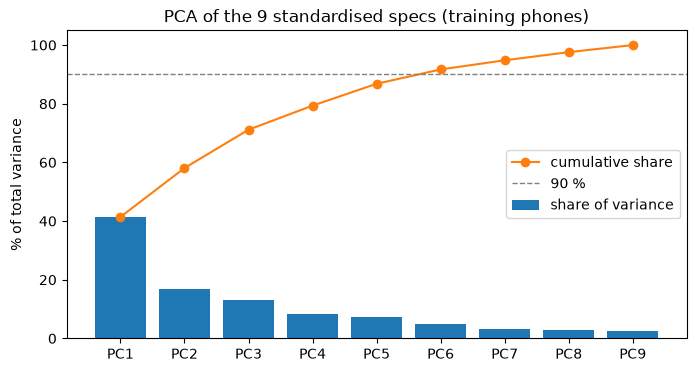

components needed for 90 % of the variance: 6 of 9


In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pc_names, 100 * pca.explained_variance_ratio_, label="share of variance")
ax.plot(pc_names, 100 * np.cumsum(pca.explained_variance_ratio_), marker="o", color="tab:orange", label="cumulative share")
ax.axhline(90, color="gray", linestyle="--", linewidth=1, label="90 %")
ax.set(title="PCA of the 9 standardised specs (training phones)", ylabel="% of total variance", ylim=(0, 105))
ax.legend()
plt.show()
k90 = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.9)) + 1
print(f"components needed for 90 % of the variance: {k90} of {pca.n_components_}")

**Loadings: what each component means.** Each column lists how strongly each spec points along that component (a loading of ±1 would mean the component is that spec alone). Large positive or negative loadings tell us what the component "is about".

In [21]:
pca_loadings = pd.DataFrame(pca.components_.T, index=NUMERIC_FEATURES, columns=pc_names)
pca_loadings[["PC1", "PC2", "PC3"]].sort_values("PC1", key=abs, ascending=False).round(2)

,PC1,PC2,PC3
log2_ram,0.41,0.33,0.05
screen_in,0.41,-0.26,0.24
log2_storage,0.35,0.32,0.17
main_back_mp,0.35,0.08,-0.38
year,0.35,-0.24,-0.26
battery_mah,0.34,-0.42,-0.13
weight_g,0.30,-0.34,0.49
front_mp,0.28,0.45,-0.36
n_back_cameras,0.09,0.40,0.57


**The phones in the PC1–PC2 plane**, coloured by log price. If PC1 is a "phone tier" axis, colour should change mainly from left to right.

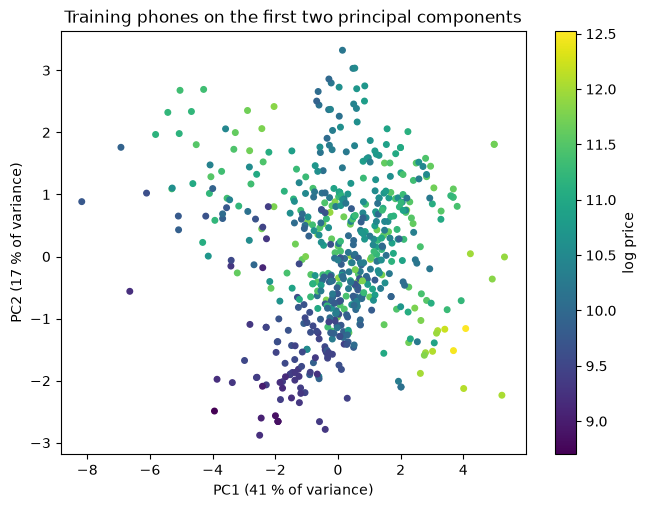

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
points = ax.scatter(pc_scores[:, 0], pc_scores[:, 1], c=train["log_price"], cmap="viridis", s=16)
fig.colorbar(points, ax=ax, label="log price")
ax.set(title="Training phones on the first two principal components",
       xlabel=f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f} % of variance)",
       ylabel=f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f} % of variance)")
plt.show()

**Save** the variance table and the loadings for the website.

In [23]:
pca_variance.rename_axis("component").to_csv("../results/pca_variance.csv")
pca_loadings.rename_axis("feature").to_csv("../results/pca_loadings.csv")
print("Saved results/pca_variance.csv and results/pca_loadings.csv")

Saved results/pca_variance.csv and results/pca_loadings.csv


**Takeaway — the specs are only moderately redundant, and the biggest direction of variation is not the price direction.**
- **PC1 explains 41 % of the variation** in the 9 specs, and all its loadings are positive (RAM 0.41, screen 0.41, storage 0.35, main camera 0.35, year 0.35, battery 0.34, weight 0.30, front camera 0.28). It is a "bigger, newer, more of everything" axis.
- **PC2 explains 17 %.** It contrasts memory and cameras (RAM +0.33, storage +0.32, front camera +0.45, number of back cameras +0.40) with battery, weight and screen (−0.42, −0.34, −0.26): "spec-rich" vs "big-battery" phones.
- **Six of the nine components are needed to keep 90 % of the variation.** If the specs were strongly redundant, two or three would be enough. This matches Phase 4's condition number of 17 (moderate collinearity), and the eigenvalues are exactly Phase 4's (121.3 to 2079.0).
- **PCA does not find the price on its own.** PCA never looks at the price, and no single component tracks it closely: PC1 correlates only 0.35 with log price and PC2 0.40. Even the smallest component, PC9 (2.4 % of the variation), correlates 0.25 with log price. A low-variance direction can still carry price information, which is why we keep all the specs in the models instead of keeping only the top components.
- **Battery loads positively on PC1 but negatively on PC2.** Large batteries come both with big, new phones (PC1) and with budget phones that skimp on memory and cameras (PC2). That is the same mixed picture behind the negative battery coefficient in Phases 4–5.

## Summary
- Cross-validation chooses **light regularisation** for all three methods (ridge α = 1.53; lasso α = 0.0014; elastic net α = 0.0017 with l1_ratio 0.8). All three reach grouped-CV **R² 0.847–0.848**, essentially equal to OLS (0.845). Regularisation buys stability, not accuracy, on this dataset.
- The **eigenvalue view** shows where ridge acts. Exact redundancies (all dummies kept) are removed completely, and the weakest real directions, brand-specific chips vs their brand (Kirin/Huawei, Tensor/Google), are shrunk to 56–63 %. Well-supported spec directions are untouched.
- **RAM vs storage:** at the chosen α ridge ≈ OLS (RAM ×2 ≈ +49 %, storage ×2 ≈ +11 %). Heavier penalties share the effect more evenly, and the lasso eventually keeps storage and drops RAM. Their combined effect (≈ +63 % for doubling both) is the robust quantity.
- **Lasso feature selection:** main camera megapixels go first and storage is the last spec to survive. Kirin and Tensor dummies are dropped in favour of their brands.
- **Ridge** (α = 1.53) is the linear model carried into the final evaluation and the brand-premium analysis.
- **PCA of the specs:** the first component ("bigger, newer, more of everything") explains 41 % of the variation, and 6 of 9 components are needed for 90 %, so the specs overlap only moderately. No single component tracks the price, so PCA is used here to understand the data, not as a model input.
